# E-Commerce Sales Data Cleaning (SQL)

Cleaning `data_learn.default.ecommerce_sales_analyst_task` using pure SQL: deduplication, status standardization, missing value handling, invalid quantity flagging, and saving as a new cleaned table.

In [0]:
%sql
-- === INSPECT: Data quality issues in the raw dataset ===
SELECT issue, count_ AS record_count
FROM (
  SELECT 'Total rows' AS issue, COUNT(*) AS count_ FROM data_learn.default.ecommerce_sales_analyst_task
  UNION ALL
  SELECT 'Duplicate order_ids', COUNT(*) FROM (
    SELECT order_id FROM data_learn.default.ecommerce_sales_analyst_task
    GROUP BY order_id HAVING COUNT(*) > 1
  )
  UNION ALL
  SELECT 'Missing region', COUNT(*) FROM data_learn.default.ecommerce_sales_analyst_task WHERE region IS NULL
  UNION ALL
  SELECT 'Missing discount_rate', COUNT(*) FROM data_learn.default.ecommerce_sales_analyst_task WHERE discount_rate IS NULL
  UNION ALL
  SELECT 'Invalid quantity (<=0)', COUNT(*) FROM data_learn.default.ecommerce_sales_analyst_task WHERE quantity <= 0
  UNION ALL
  SELECT 'Status casing issues', COUNT(*) FROM data_learn.default.ecommerce_sales_analyst_task WHERE status != INITCAP(TRIM(status))
  UNION ALL
  SELECT 'Zero or negative unit_price', COUNT(*) FROM data_learn.default.ecommerce_sales_analyst_task WHERE unit_price_inr <= 0
  UNION ALL
  SELECT 'Discount outside [0,1]', COUNT(*) FROM data_learn.default.ecommerce_sales_analyst_task WHERE discount_rate < 0 OR discount_rate > 1
)
ORDER BY record_count DESC

issue,record_count
Total rows,41
Duplicate order_ids,1
Missing region,1
Missing discount_rate,1
Invalid quantity (<=0),1
Status casing issues,1
Zero or negative unit_price,0
"Discount outside [0,1]",0


In [0]:
%sql
-- === SHOW: Problematic records before cleaning ===
SELECT 'DUPLICATE' AS issue_type, order_id, order_date, region, category, product, quantity, unit_price_inr, discount_rate, status
FROM data_learn.default.ecommerce_sales_analyst_task
WHERE order_id IN (
  SELECT order_id FROM data_learn.default.ecommerce_sales_analyst_task
  GROUP BY order_id HAVING COUNT(*) > 1
)
UNION ALL
SELECT 'NULL_REGION', order_id, order_date, region, category, product, quantity, unit_price_inr, discount_rate, status
FROM data_learn.default.ecommerce_sales_analyst_task WHERE region IS NULL
UNION ALL
SELECT 'NULL_DISCOUNT', order_id, order_date, region, category, product, quantity, unit_price_inr, discount_rate, status
FROM data_learn.default.ecommerce_sales_analyst_task WHERE discount_rate IS NULL
UNION ALL
SELECT 'INVALID_QTY', order_id, order_date, region, category, product, quantity, unit_price_inr, discount_rate, status
FROM data_learn.default.ecommerce_sales_analyst_task WHERE quantity <= 0
UNION ALL
SELECT 'STATUS_CASING', order_id, order_date, region, category, product, quantity, unit_price_inr, discount_rate, status
FROM data_learn.default.ecommerce_sales_analyst_task WHERE status != INITCAP(TRIM(status))
ORDER BY issue_type, order_id

issue_type,order_id,order_date,region,category,product,quantity,unit_price_inr,discount_rate,status
DUPLICATE,O1005,2026-09-03,North,Home,Storage Box,4,299,0.0,Delivered
DUPLICATE,O1005,2026-09-03,North,Home,Storage Box,4,299,0.0,Delivered
INVALID_QTY,O1022,2026-09-11,South,Electronics,USB-C Hub,0,2499,0.2,Returned
NULL_DISCOUNT,O1013,2026-09-07,North,Electronics,Wireless Mouse,3,799,null,Delivered
NULL_REGION,O1008,2026-09-04,null,Home,Desk Lamp,2,1299,0.05,Delivered
STATUS_CASING,O1026,2026-09-13,South,Home,Desk Lamp,2,1299,0.1,delivered


In [0]:
%sql
-- === CLEAN: Create the cleaned table with all fixes applied ===
-- 1. Deduplicate via ROW_NUMBER() (keep first row per order_id by order_date)
-- 2. Standardize status with INITCAP(TRIM())
-- 3. Fill missing region with 'Unknown'
-- 4. Fill missing discount_rate with 0.0
-- 5. Flag invalid quantity and other issues in cleaning_action column

CREATE OR REPLACE TABLE data_learn.default.ecommerce_sales_cleaned_sql AS
WITH deduped AS (
  SELECT
    order_id, order_date, region, category, product,
    quantity, unit_price_inr, discount_rate, status,
    ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY order_date) AS rn
  FROM data_learn.default.ecommerce_sales_analyst_task
),
flagged AS (
  SELECT
    order_id,
    order_date,
    COALESCE(region, 'Unknown')          AS region,
    category,
    product,
    quantity,
    unit_price_inr,
    COALESCE(discount_rate, 0.0)         AS discount_rate,
    INITCAP(TRIM(status))                AS status,
    TRIM(
      CASE WHEN region IS NULL                 THEN 'missing_region; '      ELSE '' END ||
      CASE WHEN discount_rate IS NULL           THEN 'missing_discount; '    ELSE '' END ||
      CASE WHEN quantity <= 0                   THEN 'invalid_quantity; '     ELSE '' END ||
      CASE WHEN status != INITCAP(TRIM(status)) THEN 'status_casing_fixed; ' ELSE '' END
    ) AS raw_action
  FROM deduped
  WHERE rn = 1
)
SELECT
  order_id, order_date, region, category, product,
  quantity, unit_price_inr, discount_rate, status,
  CASE WHEN raw_action = '' THEN 'none' ELSE raw_action END AS cleaning_action
FROM flagged

num_affected_rows,num_inserted_rows


In [0]:
%sql
-- === VERIFY: Cleaned data summary ===
SELECT
  COUNT(*)                                               AS total_rows,
  COUNT(DISTINCT order_id)                                AS distinct_order_ids,
  SUM(CASE WHEN region IS NULL THEN 1 ELSE 0 END)        AS null_region,
  SUM(CASE WHEN discount_rate IS NULL THEN 1 ELSE 0 END) AS null_discount_rate,
  SUM(CASE WHEN cleaning_action != 'none' THEN 1 ELSE 0 END) AS flagged_records,
  SUM(CASE WHEN quantity <= 0 THEN 1 ELSE 0 END)         AS invalid_quantity
FROM data_learn.default.ecommerce_sales_cleaned_sql

total_rows,distinct_order_ids,null_region,null_discount_rate,flagged_records,invalid_quantity
40,40,0,0,4,1


In [0]:
%sql
-- === VERIFY: Status distribution after standardization ===
SELECT status, COUNT(*) AS order_count,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM data_learn.default.ecommerce_sales_cleaned_sql), 1) AS pct
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY status
ORDER BY order_count DESC

status,order_count,pct
Delivered,36,90.0
Returned,2,5.0
Cancelled,2,5.0


In [0]:
%sql
-- === VERIFY: Flagged records for review ===
SELECT order_id, order_date, region, category, product, quantity, unit_price_inr, discount_rate, status, cleaning_action
FROM data_learn.default.ecommerce_sales_cleaned_sql
WHERE cleaning_action != 'none'
ORDER BY order_id

order_id,order_date,region,category,product,quantity,unit_price_inr,discount_rate,status,cleaning_action
O1008,2026-09-04,Unknown,Home,Desk Lamp,2,1299,0.05,Delivered,missing_region;
O1013,2026-09-07,North,Electronics,Wireless Mouse,3,799,0.0,Delivered,missing_discount;
O1022,2026-09-11,South,Electronics,USB-C Hub,0,2499,0.2,Returned,invalid_quantity;
O1026,2026-09-13,South,Home,Desk Lamp,2,1299,0.1,Delivered,status_casing_fixed;


## Sales KPI Analysis (SQL)

Computing all key metrics on the SQL-cleaned table `data_learn.default.ecommerce_sales_cleaned_sql`:
- Total orders & orders by status
- Gross merchandise value (GMV) before discounts
- Net sales after discounts
- Net sales by product category
- Average order value (AOV)
- Order cancellation & return rates

In [0]:
%sql
-- === TOTAL ORDERS, GMV, NET SALES & DISCOUNT SUMMARY ===
SELECT
  COUNT(*)                                                    AS total_orders,
  SUM(quantity * unit_price_inr)                               AS gmv_before_discounts,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)), 2) AS net_sales_after_discounts,
  ROUND(SUM(quantity * unit_price_inr) - SUM(quantity * unit_price_inr * (1 - discount_rate)), 2) AS total_discount_given,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)) / COUNT(*), 2) AS aov_all_orders,
  ROUND(SUM(CASE WHEN status = 'Cancelled' THEN 1.0 ELSE 0 END) / COUNT(*) * 100, 1) AS cancellation_rate_pct,
  ROUND(SUM(CASE WHEN status = 'Returned'  THEN 1.0 ELSE 0 END) / COUNT(*) * 100, 1) AS return_rate_pct
FROM data_learn.default.ecommerce_sales_cleaned_sql

total_orders,gmv_before_discounts,net_sales_after_discounts,total_discount_given,aov_all_orders,cancellation_rate_pct,return_rate_pct
40,82726,75546.35,7179.65,1888.66,5.0,5.0


In [0]:
%sql
-- === ORDERS BY STATUS ===
SELECT
  status,
  COUNT(*) AS order_count,
  ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct_of_total,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)), 2) AS net_sales
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY status
ORDER BY order_count DESC

status,order_count,pct_of_total,net_sales
Delivered,36,90.0,70850.15
Cancelled,2,5.0,3798.0
Returned,2,5.0,898.2


In [0]:
%sql
-- === NET SALES BY PRODUCT CATEGORY ===
SELECT
  category,
  COUNT(*) AS orders,
  SUM(quantity * unit_price_inr) AS gmv,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)), 2) AS net_sales,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)) / COUNT(*), 2) AS aov,
  ROUND((SUM(quantity * unit_price_inr) - SUM(quantity * unit_price_inr * (1 - discount_rate)))
        / SUM(quantity * unit_price_inr) * 100, 1) AS discount_pct_of_gmv
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY category
ORDER BY net_sales DESC

category,orders,gmv,net_sales,aov,discount_pct_of_gmv
Electronics,14,29580,28140.95,2010.07,4.9
Fashion,13,32475,28103.0,2161.77,13.5
Home,13,20671,19302.4,1484.8,6.6


In [0]:
%sql
-- === NET SALES BY REGION ===
SELECT
  region,
  COUNT(*) AS orders,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)), 2) AS net_sales,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)) / COUNT(*), 2) AS aov,
  ROUND((SUM(quantity * unit_price_inr) - SUM(quantity * unit_price_inr * (1 - discount_rate)))
        / SUM(quantity * unit_price_inr) * 100, 1) AS discount_pct
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY region
ORDER BY net_sales DESC

region,orders,net_sales,aov,discount_pct
East,9,26151.5,2905.72,8.8
South,10,24043.35,2404.34,11.9
West,10,12712.45,1271.25,5.7
North,10,10170.95,1017.09,4.8
Unknown,1,2468.1,2468.1,5.0


In [0]:
%sql
-- === PRODUCT PERFORMANCE ===
SELECT
  product,
  category,
  COUNT(*) AS orders,
  ROUND(SUM(quantity * unit_price_inr * (1 - discount_rate)), 2) AS net_sales,
  ROUND(AVG(unit_price_inr), 2) AS avg_price,
  ROUND(AVG(discount_rate) * 100, 1) AS avg_disc_pct,
  SUM(quantity) AS total_qty
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY product, category
ORDER BY net_sales DESC

product,category,orders,net_sales,avg_price,avg_disc_pct,total_qty
Running Shoes,Fashion,6,20543.15,2999.0,13.3,8
USB-C Hub,Electronics,7,18992.4,2499.0,7.1,8
Desk Lamp,Home,7,14353.95,1299.0,6.4,12
Wireless Mouse,Electronics,7,9148.55,799.0,5.0,12
Cotton T-Shirt,Fashion,7,7559.85,499.0,8.6,17
Storage Box,Home,6,4948.45,299.0,2.5,17


In [0]:
%sql
-- === ORDER VALUE BY DISCOUNT TIER ===
SELECT
  CASE
    WHEN discount_rate = 0 THEN '0% (no discount)'
    WHEN discount_rate <= 0.10 THEN '1-10%'
    WHEN discount_rate <= 0.20 THEN '11-20%'
    ELSE '21%+'
  END AS discount_tier,
  COUNT(*) AS orders,
  ROUND(AVG(quantity * unit_price_inr), 2) AS avg_gmv,
  ROUND(AVG(quantity * unit_price_inr * (1 - discount_rate)), 2) AS avg_net_sales,
  ROUND(AVG(quantity), 1) AS avg_qty,
  ROUND(AVG(unit_price_inr), 2) AS avg_unit_price
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY
  CASE
    WHEN discount_rate = 0 THEN '0% (no discount)'
    WHEN discount_rate <= 0.10 THEN '1-10%'
    WHEN discount_rate <= 0.20 THEN '11-20%'
    ELSE '21%+'
  END
ORDER BY avg_gmv

discount_tier,orders,avg_gmv,avg_net_sales,avg_qty,avg_unit_price
0% (no discount),14,1541.14,1541.14,1.7,1084.71
11-20%,7,2026.71,1687.03,1.9,1656.14
1-10%,18,2275.83,2092.37,1.9,1426.78
21%+,1,5998.0,4498.5,2.0,2999.0


In [0]:
%sql
-- === CANCELLATION & RETURN RATES BY REGION ===
SELECT
  region,
  COUNT(*) AS total_orders,
  SUM(CASE WHEN status = 'Cancelled' THEN 1 ELSE 0 END) AS cancelled,
  SUM(CASE WHEN status = 'Returned'  THEN 1 ELSE 0 END) AS returned,
  SUM(CASE WHEN status = 'Delivered' THEN 1 ELSE 0 END) AS delivered,
  ROUND(SUM(CASE WHEN status = 'Cancelled' THEN 1.0 ELSE 0 END) / COUNT(*) * 100, 1) AS cancel_rate_pct,
  ROUND(SUM(CASE WHEN status = 'Returned'  THEN 1.0 ELSE 0 END) / COUNT(*) * 100, 1) AS return_rate_pct
FROM data_learn.default.ecommerce_sales_cleaned_sql
GROUP BY region
ORDER BY total_orders DESC

region,total_orders,cancelled,returned,delivered,cancel_rate_pct,return_rate_pct
West,10,1,0,9,10.0,0.0
South,10,1,1,8,10.0,10.0
North,10,0,1,9,0.0,10.0
East,9,0,0,9,0.0,0.0
Unknown,1,0,0,1,0.0,0.0


## Visualizations

Charts built from the SQL KPI analysis above.

In [0]:
# Prepare data from SQL results for charting
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# KPI values (from Cell 9)
total_orders = 40
gmv = 82726
net_sales = 75546.35
discount_given = 7179.65
aov = 1888.66
cancel_rate = 5.0
return_rate = 5.0

# Status data (from Cell 10)
status_labels = ['Delivered', 'Cancelled', 'Returned']
status_counts = [36, 2, 2]
status_net = [70850.15, 3798.0, 898.2]
status_colors = ['#52A870', '#C85070', '#C89930']

# Category data (from Cell 11)
cat_labels = ['Electronics', 'Fashion', 'Home']
cat_net = [28140.95, 28103.0, 19302.4]
cat_aov = [2010.07, 2161.77, 1484.8]
cat_disc = [4.9, 13.5, 6.6]
cat_colors = ['#15AFDD', '#2375A8', '#52A870']

# Region data (from Cell 12)
reg_labels = ['East', 'South', 'West', 'North', 'Unknown']
reg_net = [26151.5, 24043.35, 12712.45, 10170.95, 2468.1]
reg_aov = [2905.72, 2404.34, 1271.25, 1017.09, 2468.1]

# Product data (from Cell 13)
prod_labels = ['Running\nShoes', 'USB-C Hub', 'Desk Lamp', 'Wireless\nMouse', 'Cotton\nT-Shirt', 'Storage Box']
prod_net = [20543.15, 18992.4, 14353.95, 9148.55, 7559.85, 4948.45]
prod_disc = [13.3, 7.1, 6.4, 5.0, 8.6, 2.5]

# Discount tier data (from Cell 14)
tier_labels = ['0%\n(no disc.)', '1-10%', '11-20%', '21%+']
tier_gmv = [1541.14, 2275.83, 2026.71, 5998.0]
tier_orders = [14, 18, 7, 1]

print("Data prepared for all charts.")

Data prepared for all charts.


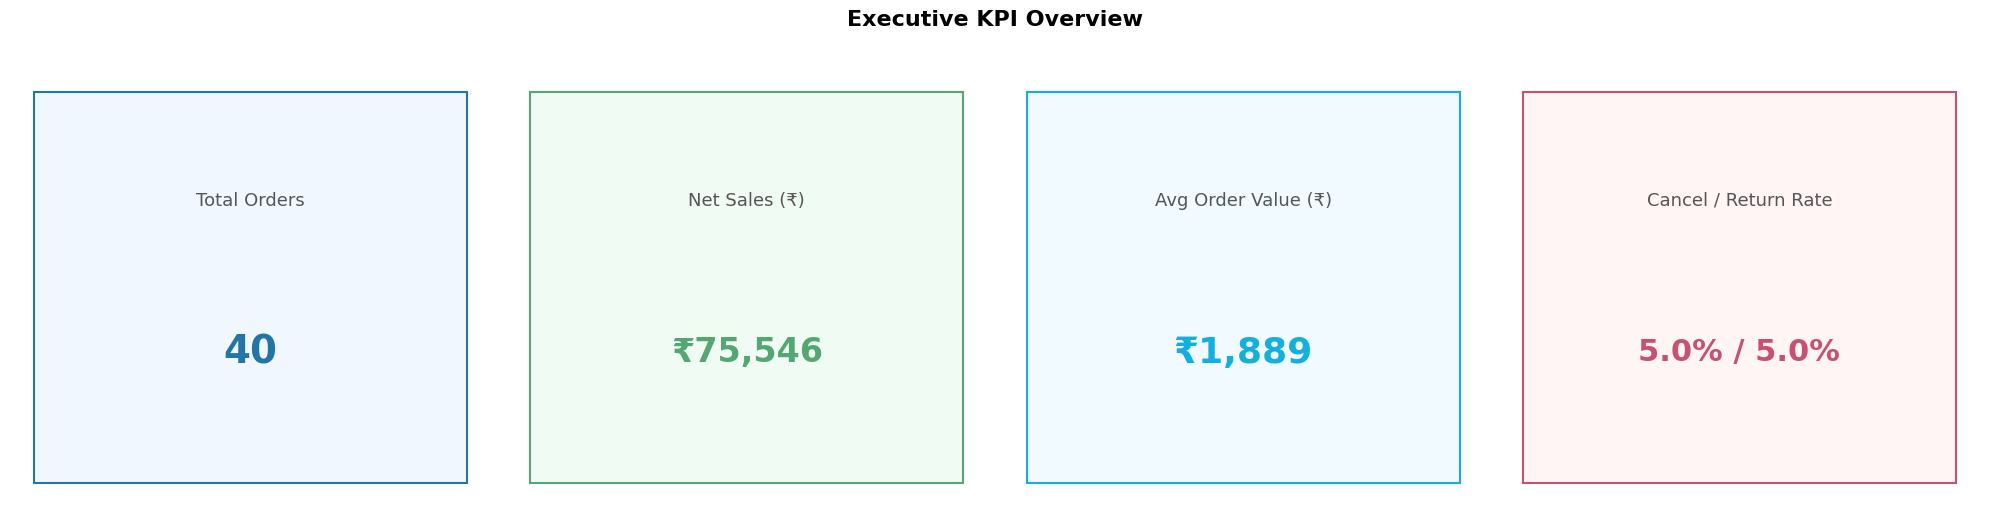

In [0]:
# Chart 1: KPI Summary Cards + Orders by Status Pie
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Executive KPI Overview', fontsize=16, fontweight='bold', y=1.02)

# KPI text cards
kpi_text = f"Total Orders\n{total_orders:,}"
axes[0].text(0.5, 0.7, 'Total Orders', ha='center', va='center', fontsize=13, color='#555')
axes[0].text(0.5, 0.35, f'{total_orders:,}', ha='center', va='center', fontsize=28, fontweight='bold', color='#2375A8')
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1); axes[0].axis('off')
axes[0].add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.9, fill=True, facecolor='#F0F7FF', edgecolor='#2375A8', linewidth=1.5, transform=axes[0].transAxes, zorder=0))

axes[1].text(0.5, 0.7, 'Net Sales (₹)', ha='center', va='center', fontsize=13, color='#555')
axes[1].text(0.5, 0.35, f'₹{net_sales:,.0f}', ha='center', va='center', fontsize=24, fontweight='bold', color='#52A870')
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1); axes[1].axis('off')
axes[1].add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.9, fill=True, facecolor='#F0FBF4', edgecolor='#52A870', linewidth=1.5, transform=axes[1].transAxes, zorder=0))

axes[2].text(0.5, 0.7, 'Avg Order Value (₹)', ha='center', va='center', fontsize=13, color='#555')
axes[2].text(0.5, 0.35, f'₹{aov:,.0f}', ha='center', va='center', fontsize=26, fontweight='bold', color='#15AFDD')
axes[2].set_xlim(0, 1); axes[2].set_ylim(0, 1); axes[2].axis('off')
axes[2].add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.9, fill=True, facecolor='#F0FAFF', edgecolor='#15AFDD', linewidth=1.5, transform=axes[2].transAxes, zorder=0))

axes[3].text(0.5, 0.7, 'Cancel / Return Rate', ha='center', va='center', fontsize=13, color='#555')
axes[3].text(0.5, 0.35, f'{cancel_rate}% / {return_rate}%', ha='center', va='center', fontsize=22, fontweight='bold', color='#C85070')
axes[3].set_xlim(0, 1); axes[3].set_ylim(0, 1); axes[3].axis('off')
axes[3].add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.9, fill=True, facecolor='#FFF5F5', edgecolor='#C85070', linewidth=1.5, transform=axes[3].transAxes, zorder=0))

plt.tight_layout()
display(fig)
plt.close(fig)

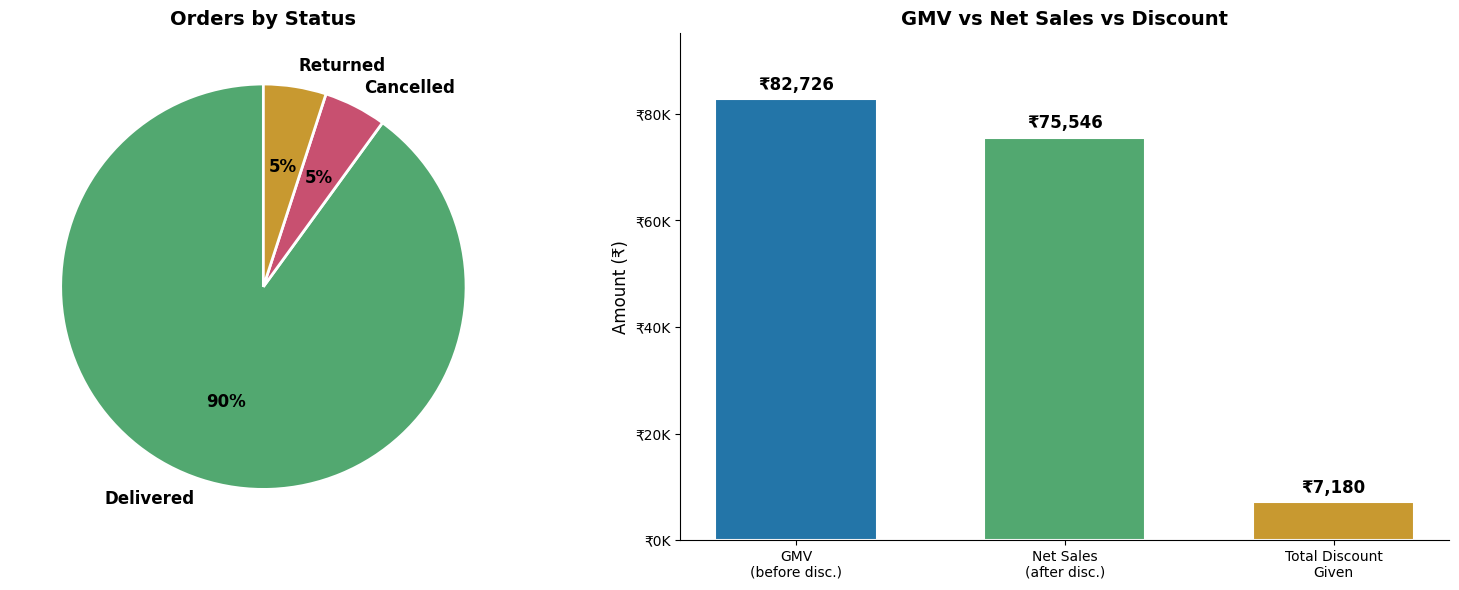

In [0]:
# Chart 2: Orders by Status (Pie) + GMV vs Net Sales (Bar)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pie chart - Orders by Status
axes[0].pie(status_counts, labels=status_labels, colors=status_colors, autopct='%1.0f%%',
            startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Orders by Status', fontsize=14, fontweight='bold')

# Bar chart - GMV vs Net Sales vs Discount
bar_labels = ['GMV\n(before disc.)', 'Net Sales\n(after disc.)', 'Total Discount\nGiven']
bar_values = [gmv, net_sales, discount_given]
bar_colors = ['#2375A8', '#52A870', '#C89930']
bars = axes[1].bar(bar_labels, bar_values, color=bar_colors, edgecolor='white', linewidth=1.5, width=0.6)
axes[1].set_title('GMV vs Net Sales vs Discount', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Amount (₹)', fontsize=12)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}K'))
for bar, val in zip(bars, bar_values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
                f'₹{val:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, max(bar_values) * 1.15)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

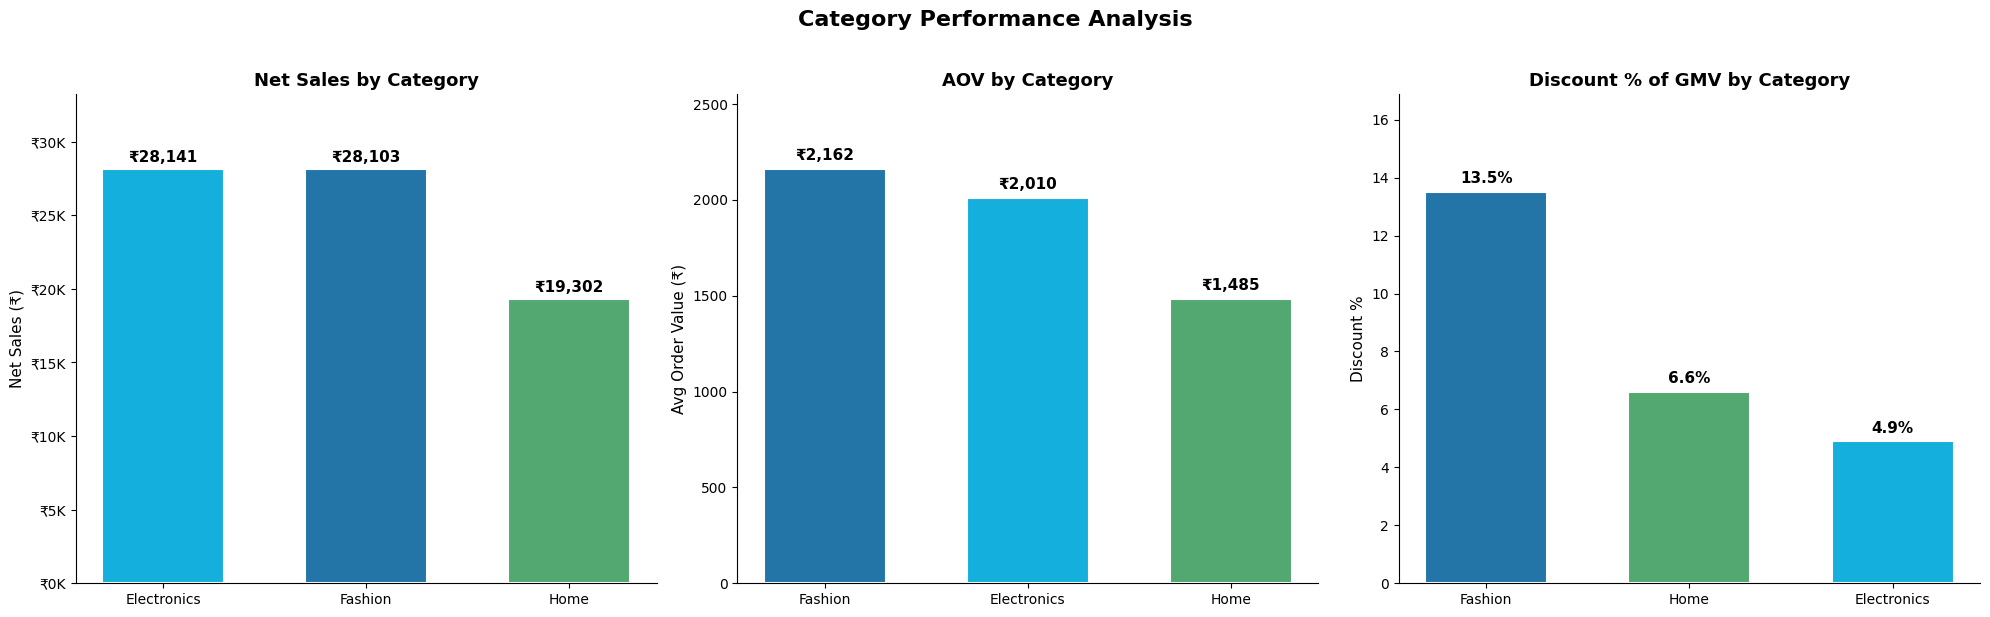

In [0]:
# Chart 3: Net Sales by Category + AOV by Category + Discount % by Category
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Category Performance Analysis', fontsize=16, fontweight='bold', y=1.02)

# Net Sales by Category
sorted_idx = np.argsort(cat_net)[::-1]
bars = axes[0].bar([cat_labels[i] for i in sorted_idx], [cat_net[i] for i in sorted_idx],
                   color=[cat_colors[i] for i in sorted_idx], edgecolor='white', linewidth=1.5, width=0.6)
axes[0].set_title('Net Sales by Category', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Net Sales (₹)', fontsize=11)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}K'))
for bar, val in zip(bars, [cat_net[i] for i in sorted_idx]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                f'₹{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, max(cat_net) * 1.18)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# AOV by Category
sorted_aov = np.argsort(cat_aov)[::-1]
bars = axes[1].bar([cat_labels[i] for i in sorted_aov], [cat_aov[i] for i in sorted_aov],
                   color=[cat_colors[i] for i in sorted_aov], edgecolor='white', linewidth=1.5, width=0.6)
axes[1].set_title('AOV by Category', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Avg Order Value (₹)', fontsize=11)
for bar, val in zip(bars, [cat_aov[i] for i in sorted_aov]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                f'₹{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, max(cat_aov) * 1.18)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

# Discount % by Category
sorted_disc = np.argsort(cat_disc)[::-1]
bars = axes[2].bar([cat_labels[i] for i in sorted_disc], [cat_disc[i] for i in sorted_disc],
                   color=[cat_colors[i] for i in sorted_disc], edgecolor='white', linewidth=1.5, width=0.6)
axes[2].set_title('Discount % of GMV by Category', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Discount %', fontsize=11)
for bar, val in zip(bars, [cat_disc[i] for i in sorted_disc]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f'{val}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[2].set_ylim(0, max(cat_disc) * 1.25)
axes[2].spines['top'].set_visible(False); axes[2].spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

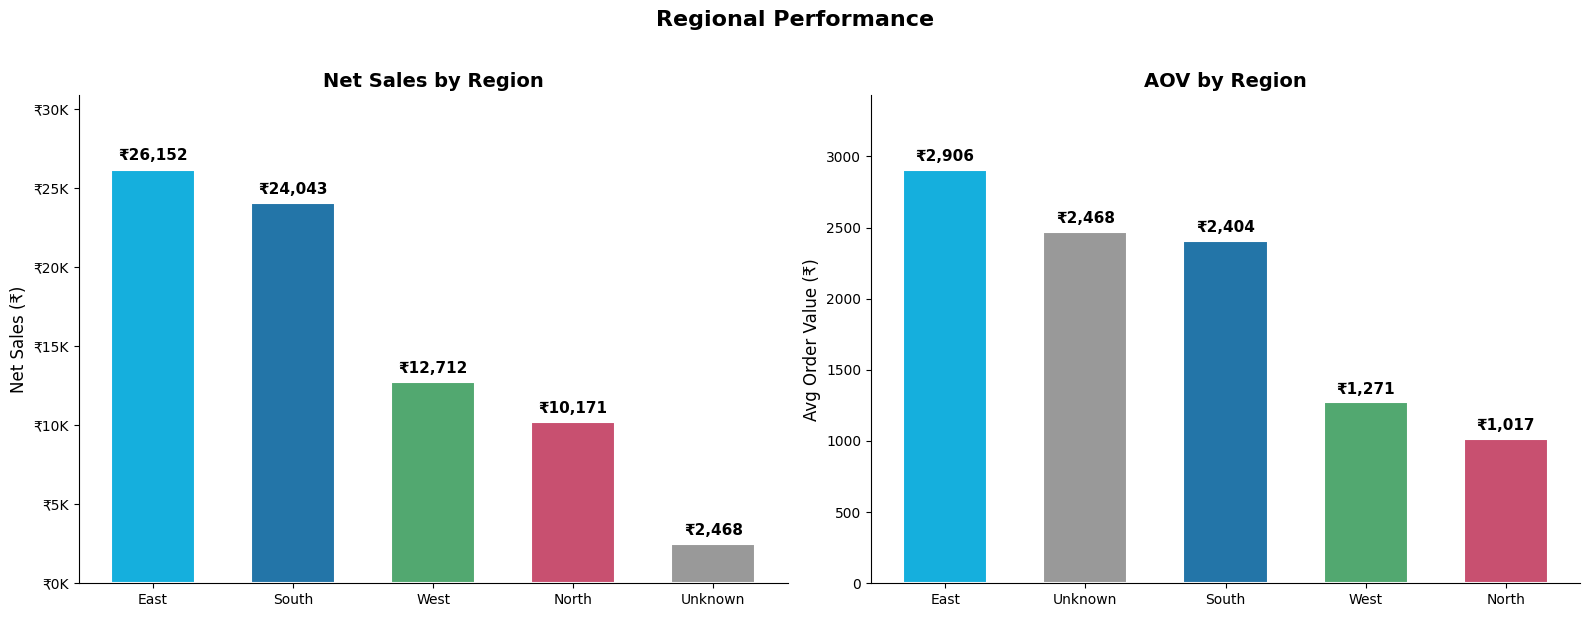

In [0]:
# Chart 4: Net Sales by Region + AOV by Region
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Regional Performance', fontsize=16, fontweight='bold', y=1.02)
reg_colors = ['#15AFDD', '#2375A8', '#52A870', '#C85070', '#999999']

# Net Sales by Region
sorted_r = np.argsort(reg_net)[::-1]
bars = axes[0].bar([reg_labels[i] for i in sorted_r], [reg_net[i] for i in sorted_r],
                   color=[reg_colors[i] for i in sorted_r], edgecolor='white', linewidth=1.5, width=0.6)
axes[0].set_title('Net Sales by Region', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Net Sales (₹)', fontsize=12)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}K'))
for bar, val in zip(bars, [reg_net[i] for i in sorted_r]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
                f'₹{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, max(reg_net) * 1.18)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# AOV by Region
sorted_a = np.argsort(reg_aov)[::-1]
bars = axes[1].bar([reg_labels[i] for i in sorted_a], [reg_aov[i] for i in sorted_a],
                   color=[reg_colors[i] for i in sorted_a], edgecolor='white', linewidth=1.5, width=0.6)
axes[1].set_title('AOV by Region', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Avg Order Value (₹)', fontsize=12)
for bar, val in zip(bars, [reg_aov[i] for i in sorted_a]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 40,
                f'₹{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, max(reg_aov) * 1.18)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

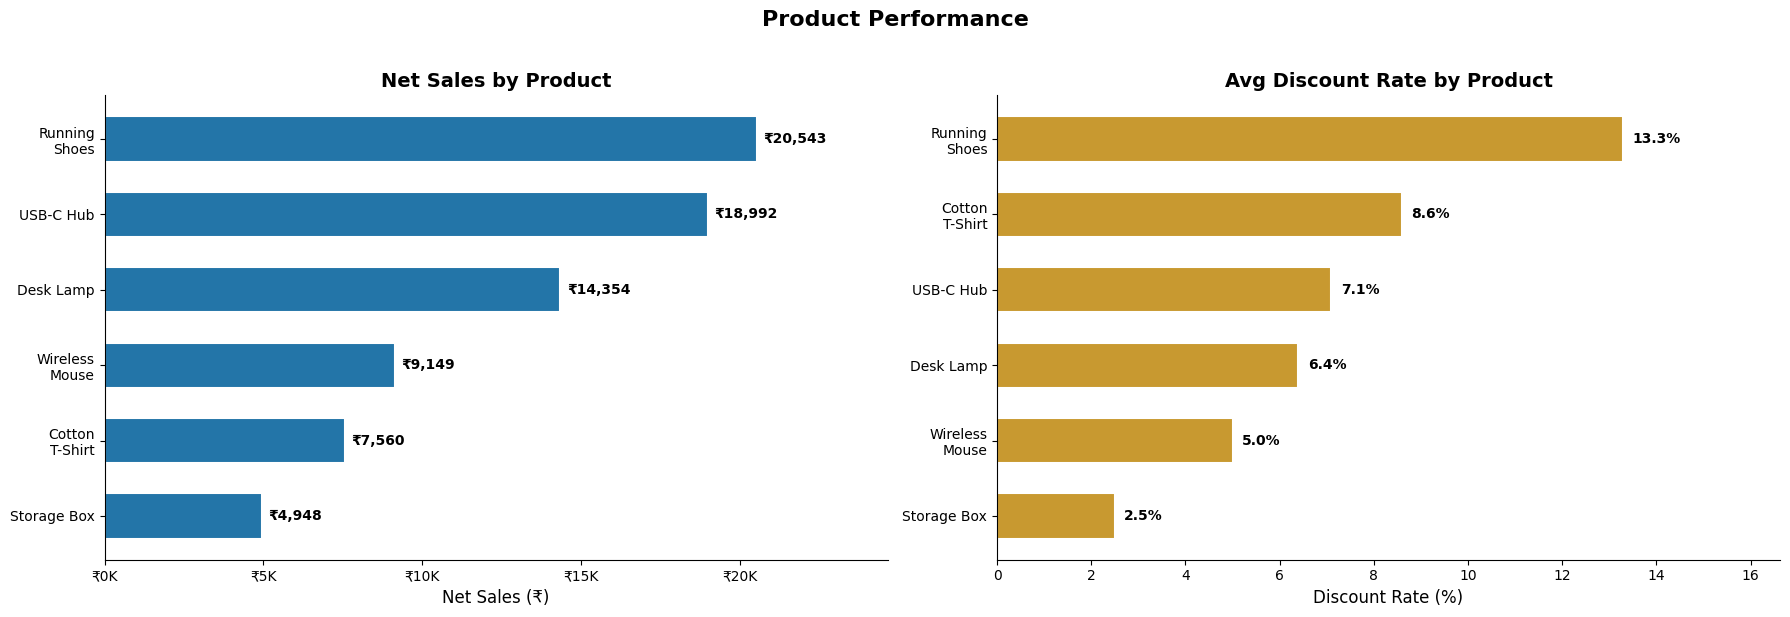

In [0]:
# Chart 5: Product Net Sales (horizontal bar) + Avg Discount Rate by Product
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Product Performance', fontsize=16, fontweight='bold', y=1.02)

# Net Sales by Product (horizontal bar)
sorted_p = np.argsort(prod_net)
bars = axes[0].barh([prod_labels[i] for i in sorted_p], [prod_net[i] for i in sorted_p],
                    color='#2375A8', edgecolor='white', linewidth=1.5, height=0.6)
axes[0].set_title('Net Sales by Product', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Net Sales (₹)', fontsize=12)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}K'))
for bar, val in zip(bars, [prod_net[i] for i in sorted_p]):
    axes[0].text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2,
                f'₹{val:,.0f}', ha='left', va='center', fontsize=10, fontweight='bold')
axes[0].set_xlim(0, max(prod_net) * 1.2)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# Avg Discount Rate by Product
sorted_d = np.argsort(prod_disc)
bars = axes[1].barh([prod_labels[i] for i in sorted_d], [prod_disc[i] for i in sorted_d],
                    color='#C89930', edgecolor='white', linewidth=1.5, height=0.6)
axes[1].set_title('Avg Discount Rate by Product', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Discount Rate (%)', fontsize=12)
for bar, val in zip(bars, [prod_disc[i] for i in sorted_d]):
    axes[1].text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                f'{val}%', ha='left', va='center', fontsize=10, fontweight='bold')
axes[1].set_xlim(0, max(prod_disc) * 1.25)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

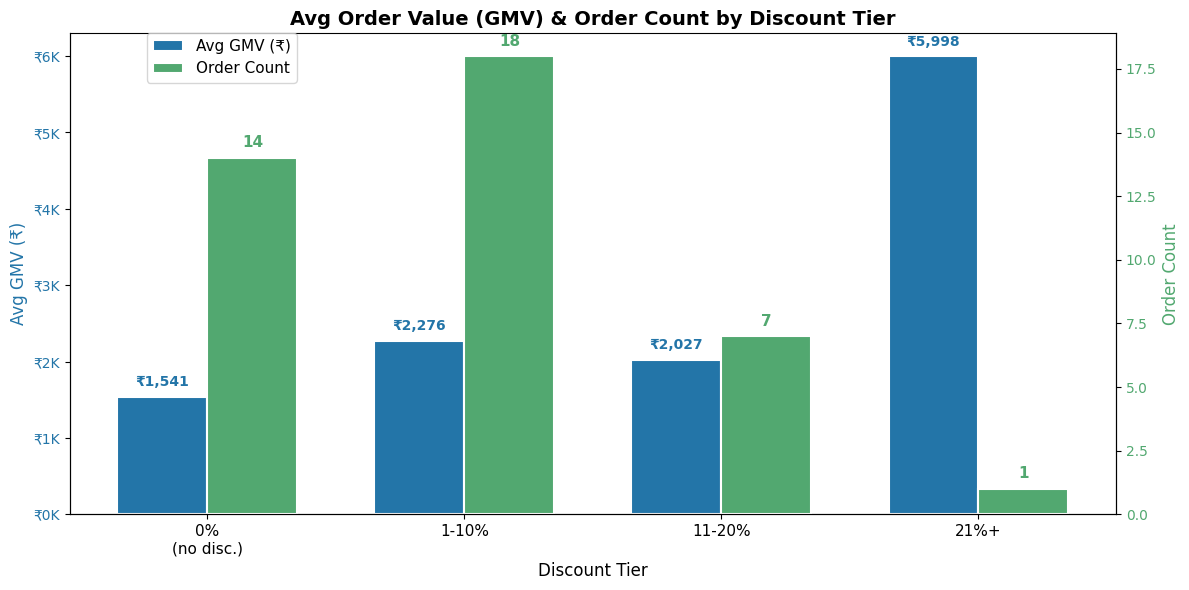

In [0]:
# Chart 6: Order Value by Discount Tier (avg GMV + order count)
fig, ax1 = plt.subplots(figsize=(12, 6))

x = np.arange(len(tier_labels))
width = 0.35

bars1 = ax1.bar(x - width/2, tier_gmv, width, label='Avg GMV (₹)', color='#2375A8',
                edgecolor='white', linewidth=1.5)
ax1.set_xlabel('Discount Tier', fontsize=12)
ax1.set_ylabel('Avg GMV (₹)', fontsize=12, color='#2375A8')
ax1.tick_params(axis='y', labelcolor='#2375A8')
ax1.set_xticks(x)
ax1.set_xticklabels(tier_labels, fontsize=11)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'₹{v/1000:.0f}K'))

for bar, val in zip(bars1, tier_gmv):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
             f'₹{val:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2375A8')

ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, tier_orders, width, label='Order Count', color='#52A870',
                edgecolor='white', linewidth=1.5)
ax2.set_ylabel('Order Count', fontsize=12, color='#52A870')
ax2.tick_params(axis='y', labelcolor='#52A870')

for bar, val in zip(bars2, tier_orders):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(val), ha='center', va='bottom', fontsize=11, fontweight='bold', color='#52A870')

ax1.set_title('Avg Order Value (GMV) & Order Count by Discount Tier', fontsize=14, fontweight='bold')
ax1.spines['top'].set_visible(False)

fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.95), fontsize=11)
plt.tight_layout()
display(fig)
plt.close(fig)

# SQL Analysis Summary

## Key Findings

### 1. Revenue & Discount Impact
* **GMV (before discounts):** ₹82,726 across 40 orders
* **Net Sales (after discounts):** ₹75,546.35 — meaning ₹7,179.65 (8.7% of GMV) was given up to discounts
* **Average Order Value (AOV):** ₹1,888.66, reflecting a mix of low-ticket (Storage Box ₹299) and high-ticket (Running Shoes ₹2,999) products

### 2. Category Performance
* **Electronics** leads in net sales (₹28,140.95) with the most orders (14) but the **lowest discount rate** (4.9% of GMV), indicating strong full-price demand
* **Fashion** has the **highest AOV** (₹2,161.77) despite a mid-range order count (13), driven by premium products like Running Shoes (₹2,999 avg price). However, it carries the **heaviest discount burden** at 13.5% of GMV
* **Home** category lags in both net sales (₹19,302.40) and AOV (₹1,484.80), suggesting lower-priced items with thinner margins

### 3. Regional Insights
* **East** region generates the **highest net sales** (₹26,151.50) with the **highest AOV** (₹2,905.72) despite having only 9 orders — fewer but larger orders
* **South** matches East in order count (10) but has a **higher discount rate** (11.9% vs 8.8%), resulting in lower net sales (₹24,043.35)
* **North** has the **lowest AOV** (₹1,017.09) and lowest discount rate (4.8%) — small, full-price orders
* **Unknown** region (1 order, originally null) contributes ₹2,468.10 in net sales

### 4. Product Standouts
* **Running Shoes** is the top revenue product (₹20,543.15 net sales) but also has the **highest avg discount rate** (13.3%) — revenue depends heavily on promotions
* **USB-C Hub** is the second-highest (₹18,992.40) with moderate discounts (7.1%) — a balanced performer
* **Cotton T-Shirt** and **Storage Box** are volume drivers (17 units each) but low revenue due to low unit prices (₹499 and ₹299)

### 5. Discount Tier Patterns
* **45% of orders** (18 of 40) fall in the 1–10% discount tier, making it the most common discount range
* **35% of orders** (14 of 40) have zero discount, showing a healthy segment of full-price purchases
* The **21%+ tier** has only 1 order but the highest avg GMV (₹5,998), suggesting deep discounts are used selectively on high-value items
* Higher discount tiers correlate with **higher avg GMV** but **fewer orders**, indicating discounts are applied to larger baskets, not broadly

### 6. Cancellation & Return Rates
* Overall **5% cancellation rate** and **5% return rate** — 2 orders each
* **South** is the only region with both a cancellation and a return (10% each), flagging it as the most problematic region
* **East** has **zero cancellations and zero returns** — the most reliable region
* **West** has 1 cancellation (10%) but no returns; **North** has 1 return (10%) but no cancellations

## Recommendations

1. **Optimize Fashion discounts:** Fashion's 13.5% discount rate is nearly 3× Electronics' 4.9%, yet net sales are nearly identical (₹28,103 vs ₹28,141). Reducing Fashion discounts by 3–5 percentage points could recover ₹800–₹1,400 in revenue without significantly impacting order volume

2. **Investigate South region issues:** South is the only region with both cancellations and returns, and it has the second-highest discount rate (11.9%). Review product quality, delivery reliability, and discounting practices in this region to reduce churn

## Limitations

* The dataset contains only 40 rows after cleaning, limiting statistical significance — trends observed may not generalize to larger datasets
* The `Unknown` region (1 order from a null region value) cannot be meaningfully analyzed and was imputed with a placeholder
* Discount rate correlation with order value is suggestive but not statistically validated due to small sample size

## Follow-up Question

* How would net sales change if Fashion discounts were reduced from 13.5% to 10% of GMV, assuming order volume remains constant? A what-if scenario on the cleaned table could quantify the revenue recovery opportunity.

# SQL vs Python: Comparative Analysis

Both approaches cleaned the same raw dataset (`data_learn.default.ecommerce_sales_analyst_task`) and produced equivalent business metrics. Below is a side-by-side comparison of the two workflows.

## Methodology Comparison

| Dimension | Python (PySpark) | SQL |
| --- | --- | --- |
| **Language** | PySpark DataFrame API (`df.withColumn`, `dropDuplicates`, etc.) | Pure SQL (`CREATE OR REPLACE TABLE`, CTEs, window functions) |
| **Deduplication** | `dropDuplicates(['order_id'])` — keeps an arbitrary first row | `ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY order_date)` — deterministic, keeps earliest order |
| **Status Standardization** | `initcap(trim(col('status')))` via `withColumn` | `INITCAP(TRIM(status))` inside a CTE |
| **Missing Value Handling** | `.fillna({'region': 'Unknown', 'discount_rate': 0.0})` | `COALESCE(region, 'Unknown')`, `COALESCE(discount_rate, 0.0)` |
| **Cleaning Action Flag** | Built sequentially with multiple `when().otherwise()` chains on the already-standardized DataFrame | Built in a single CTE using `CASE WHEN` on the **original** values before transformation |
| **Output Table** | `data_learn.default.ecommerce_sales_cleaned` (saved via `df.write.saveAsTable`) | `data_learn.default.ecommerce_sales_cleaned_sql` (saved via `CREATE OR REPLACE TABLE AS`) |
| **Execution Engine** | Spark DataFrame operations (lazy evaluation, Catalyst optimizer) | SQL compiler (same Spark engine, SQL planner) |
| **Readability** | Multi-step imperative pipeline — easy to debug step-by-step | Single declarative query — compact but harder to debug intermediate stages |
| **Flexibility** | Full Python ecosystem (pandas interop, ML libraries, custom UDFs) | Limited to SQL functions and built-in operators |
| **Reproducibility** | Depends on cell execution order and DataFrame state | Fully self-contained — one `CREATE TABLE` statement reproduces everything |

## Cleaning Results Comparison

| Metric | Python (PySpark) | SQL | Match? |
| --- | --- | --- | --- |
| Input rows | 41 | 41 | ✅ |
| Output rows | 40 | 40 | ✅ |
| Duplicate removed | 1 (order_id O1005) | 1 (order_id O1005) | ✅ |
| Null region filled | 1 → 'Unknown' | 1 → 'Unknown' | ✅ |
| Null discount filled | 1 → 0.0 | 1 → 0.0 | ✅ |
| Status standardized | 'delivered' → 'Delivered' | 'delivered' → 'Delivered' | ✅ |
| Flagged records | **3** | **4** | ❌ |
| Output columns | 10 | 10 | ✅ |

### Why the Flagged Record Count Differs

The SQL version found **4 flagged records** while the Python version found **3**. The difference is the `status_casing_fixed` flag for order `O1026`.

* **SQL** computes the `cleaning_action` flag inside a CTE that references the **original** `status` value *before* `INITCAP` is applied. So `status != INITCAP(TRIM(status))` correctly evaluates to `true` for `'delivered'` vs `'Delivered'`.
* **Python** applies `initcap(trim(col('status')))` to the DataFrame first, then later checks `col('status') != initcap(trim(col('status')))` on the **already-standardized** column. By that point, the value is already `'Delivered'`, so the condition is always `false` and the flag is never set.

> **The SQL approach is more accurate** — it captures the status casing fix as a cleaning action, which the Python approach missed.

## KPI Results Comparison

| KPI | Python (PySpark) | SQL | Match? |
| --- | --- | --- | --- |
| Total Orders | 40 | 40 | ✅ |
| GMV (before discounts) | ₹82,726 | ₹82,726 | ✅ |
| Net Sales (after discounts) | ₹75,546.35 | ₹75,546.35 | ✅ |
| Total Discount Given | ₹7,179.65 | ₹7,179.65 | ✅ |
| AOV | ₹1,888.66 | ₹1,888.66 | ✅ |
| Cancellation Rate | 5.0% | 5.0% | ✅ |
| Return Rate | 5.0% | 5.0% | ✅ |
| Delivered / Cancelled / Returned | 36 / 2 / 2 | 36 / 2 / 2 | ✅ |

All business metrics match exactly, confirming both cleaning approaches produce identical analytical results.

## Pros and Cons

### Python (PySpark)

**Advantages:**
* Step-by-step debugging — inspect any intermediate DataFrame with `display()`
* Rich ecosystem — integrate pandas, scikit-learn, MLflow, custom UDFs
* Flexible control flow — loops, conditionals, try/except error handling
* Interactive exploration — `display(df)` renders rich HTML tables and charts

**Disadvantages:**
* Mutable DataFrame state — re-running cells out of order can produce inconsistent results
* More verbose for simple transformations (multiple `withColumn` chains)
* Flag computation after transformation can miss pre-cleaning issues (as seen with status casing)
* Harder to audit — the full cleaning logic spans multiple cells and DataFrame versions

### SQL

**Advantages:**
* **Declarative and self-contained** — the entire cleaning pipeline is a single `CREATE TABLE` statement, fully reproducible
* **Deterministic** — `ROW_NUMBER()` with explicit `ORDER BY` guarantees which row is kept during deduplication
* **Pre-transformation flagging** — CTEs allow referencing original values before they are changed, catching issues the Python approach missed
* **Portable** — the same SQL runs in any Databricks SQL warehouse, notebook, or job without Python dependencies
* **Auditable** — a single query is easy to review, version-control, and share with analysts who may not know Python

**Disadvantages:**
* Harder to debug intermediate stages (no `display()` of CTE steps)
* Limited to SQL functions — no ML libraries, custom Python logic, or pandas interop
* Less flexible for iterative exploration (must rewrite the full query to change logic)

## Summary

Both approaches are valid and produce identical business metrics. The **SQL approach is better suited** for this cleaning task because:
1. It is fully reproducible in a single statement
2. It deterministically selects which duplicate to keep
3. It correctly flags all pre-cleaning issues (including status casing)
4. It is portable and auditable by analysts without Python knowledge

The **Python approach is better suited** when the workflow requires ML integration, custom logic beyond SQL's capabilities, or iterative step-by-step exploration.

## Recommendation

For data cleaning and KPI computation tasks like this one, **SQL should be the default** — it is simpler, more reproducible, and less error-prone. Python should be reserved for downstream analytics that require ML, statistical modeling, or complex data transformations that SQL cannot express declaratively.

## What-If Discount Scenario

**Question:** How would net sales change if Fashion discounts were reduced from 13.5% to 10% of GMV, assuming order volume remains constant?

This scenario tests three discount reduction targets for Fashion (10%, 8%, 5%) and compares against the current state. It also computes the impact across all categories to identify the total revenue recovery opportunity.

In [0]:
%sql
-- === WHAT-IF: Fashion net sales at reduced discount rates ===
-- Assumes order volume and GMV stay constant; only the discount_rate changes for Fashion orders.
WITH fashion_orders AS (
  SELECT
    order_id,
    quantity * unit_price_inr AS order_gmv,
    discount_rate AS current_disc,
    quantity * unit_price_inr * (1 - discount_rate) AS current_net
  FROM data_learn.default.ecommerce_sales_cleaned_sql
  WHERE category = 'Fashion'
)
SELECT
  'Current (avg 13.5%)'                            AS scenario,
  ROUND(SUM(order_gmv), 2)                         AS gmv,
  ROUND(AVG(current_disc) * 100, 1)                AS avg_disc_pct,
  ROUND(SUM(current_net), 2)                       AS net_sales,
  0.0                                              AS revenue_delta
FROM fashion_orders
UNION ALL
SELECT
  'Reduced to 10%',
  ROUND(SUM(order_gmv), 2),
  10.0,
  ROUND(SUM(order_gmv * 0.90), 2),
  ROUND(SUM(order_gmv * 0.90) - SUM(current_net), 2)
FROM fashion_orders
UNION ALL
SELECT
  'Reduced to 8%',
  ROUND(SUM(order_gmv), 2),
  8.0,
  ROUND(SUM(order_gmv * 0.92), 2),
  ROUND(SUM(order_gmv * 0.92) - SUM(current_net), 2)
FROM fashion_orders
UNION ALL
SELECT
  'Reduced to 5%',
  ROUND(SUM(order_gmv), 2),
  5.0,
  ROUND(SUM(order_gmv * 0.95), 2),
  ROUND(SUM(order_gmv * 0.95) - SUM(current_net), 2)
FROM fashion_orders
ORDER BY avg_disc_pct

scenario,gmv,avg_disc_pct,net_sales,revenue_delta
Reduced to 5%,32475,5.0,30851.25,2748.25
Reduced to 8%,32475,8.0,29877.0,1774.0
Reduced to 10%,32475,10.0,29227.5,1124.5
Current (avg 13.5%),32475,10.8,28103.0,0.0


In [0]:
%sql
-- === WHAT-IF: All categories — current vs uniform 10% cap on discounts ===
-- What if ALL categories capped discounts at 10%? Compare current net sales vs hypothetical.
WITH order_gmv AS (
  SELECT
    category,
    quantity * unit_price_inr AS gmv,
    discount_rate,
    quantity * unit_price_inr * (1 - discount_rate) AS current_net
  FROM data_learn.default.ecommerce_sales_cleaned_sql
)
SELECT
  category,
  COUNT(*) AS orders,
  ROUND(SUM(gmv), 2) AS gmv,
  ROUND(AVG(discount_rate) * 100, 1) AS current_avg_disc_pct,
  ROUND(SUM(current_net), 2) AS current_net_sales,
  ROUND(SUM(gmv * (1 - LEAST(discount_rate, 0.10))), 2) AS capped_net_sales,
  ROUND(SUM(gmv * (1 - LEAST(discount_rate, 0.10))) - SUM(current_net), 2) AS revenue_recovered
FROM order_gmv
GROUP BY category
ORDER BY revenue_recovered DESC

category,orders,gmv,current_avg_disc_pct,current_net_sales,capped_net_sales,revenue_recovered
Fashion,13,32475,10.8,28103.0,29727.0,1624.0
Home,13,20671,4.6,19302.4,19497.25,194.85
Electronics,14,29580,6.1,28140.95,28180.9,39.95


In [0]:
%sql
-- === WHAT-IF: Order-level impact for Fashion orders at 10% cap ===
SELECT
  order_id,
  product,
  quantity,
  unit_price_inr,
  ROUND(discount_rate * 100, 1) AS current_disc_pct,
  ROUND(quantity * unit_price_inr, 2) AS gmv,
  ROUND(quantity * unit_price_inr * (1 - discount_rate), 2) AS current_net,
  ROUND(quantity * unit_price_inr * (1 - LEAST(discount_rate, 0.10)), 2) AS capped_net,
  ROUND(
    quantity * unit_price_inr * (1 - LEAST(discount_rate, 0.10))
    - quantity * unit_price_inr * (1 - discount_rate),
    2
  ) AS revenue_recovered
FROM data_learn.default.ecommerce_sales_cleaned_sql
WHERE category = 'Fashion'
ORDER BY revenue_recovered DESC

order_id,product,quantity,unit_price_inr,current_disc_pct,gmv,current_net,capped_net,revenue_recovered
O1030,Running Shoes,2,2999,25.0,5998,4498.5,5398.2,899.7
O1006,Running Shoes,1,2999,20.0,2999,2399.2,2699.1,299.9
O1015,Cotton T-Shirt,4,499,20.0,1996,1596.8,1796.4,199.6
O1024,Running Shoes,1,2999,15.0,2999,2549.15,2699.1,149.95
O1004,Cotton T-Shirt,3,499,15.0,1497,1272.45,1347.3,74.85
O1012,Running Shoes,2,2999,10.0,5998,5398.2,5398.2,0.0
O1033,Cotton T-Shirt,3,499,10.0,1497,1347.3,1347.3,0.0
O1036,Running Shoes,1,2999,10.0,2999,2699.1,2699.1,0.0
O1021,Cotton T-Shirt,1,499,0.0,499,499.0,499.0,0.0
O1009,Cotton T-Shirt,2,499,10.0,998,898.2,898.2,0.0


In [0]:
%sql
-- === WHAT-IF: Total company-level net sales under each scenario ===
WITH base AS (
  SELECT
    SUM(quantity * unit_price_inr) AS total_gmv,
    SUM(quantity * unit_price_inr * (1 - discount_rate)) AS current_net
  FROM data_learn.default.ecommerce_sales_cleaned_sql
),
fashion AS (
  SELECT SUM(quantity * unit_price_inr) AS fashion_gmv,
         SUM(quantity * unit_price_inr * (1 - discount_rate)) AS fashion_current_net
  FROM data_learn.default.ecommerce_sales_cleaned_sql
  WHERE category = 'Fashion'
)
SELECT
  'Current state' AS scenario,
  ROUND(current_net, 2) AS total_net_sales,
  0.0 AS revenue_delta,
  ROUND(current_net / total_gmv * 100, 1) AS net_margin_pct
FROM base
UNION ALL
SELECT 'Fashion → 10% disc',
  ROUND(current_net + (fashion_gmv * 0.90 - fashion_current_net), 2),
  ROUND(fashion_gmv * 0.90 - fashion_current_net, 2),
  ROUND((current_net + (fashion_gmv * 0.90 - fashion_current_net)) / total_gmv * 100, 1)
FROM base, fashion
UNION ALL
SELECT 'Fashion → 8% disc',
  ROUND(current_net + (fashion_gmv * 0.92 - fashion_current_net), 2),
  ROUND(fashion_gmv * 0.92 - fashion_current_net, 2),
  ROUND((current_net + (fashion_gmv * 0.92 - fashion_current_net)) / total_gmv * 100, 1)
FROM base, fashion
UNION ALL
SELECT 'Fashion → 5% disc',
  ROUND(current_net + (fashion_gmv * 0.95 - fashion_current_net), 2),
  ROUND(fashion_gmv * 0.95 - fashion_current_net, 2),
  ROUND((current_net + (fashion_gmv * 0.95 - fashion_current_net)) / total_gmv * 100, 1)
FROM base, fashion
UNION ALL
SELECT 'All cats → 10% cap',
  ROUND(SUM(quantity * unit_price_inr * (1 - LEAST(discount_rate, 0.10))), 2),
  ROUND(SUM(quantity * unit_price_inr * (1 - LEAST(discount_rate, 0.10))) - current_net, 2),
  ROUND(SUM(quantity * unit_price_inr * (1 - LEAST(discount_rate, 0.10))) / total_gmv * 100, 1)
FROM data_learn.default.ecommerce_sales_cleaned_sql, base
GROUP BY current_net, total_gmv
ORDER BY total_net_sales

scenario,total_net_sales,revenue_delta,net_margin_pct
Current state,75546.35,0.0,91.3
Fashion → 10% disc,76670.85,1124.5,92.7
Fashion → 8% disc,77320.35,1774.0,93.5
All cats → 10% cap,77405.15,1858.8,93.6
Fashion → 5% disc,78294.6,2748.25,94.6


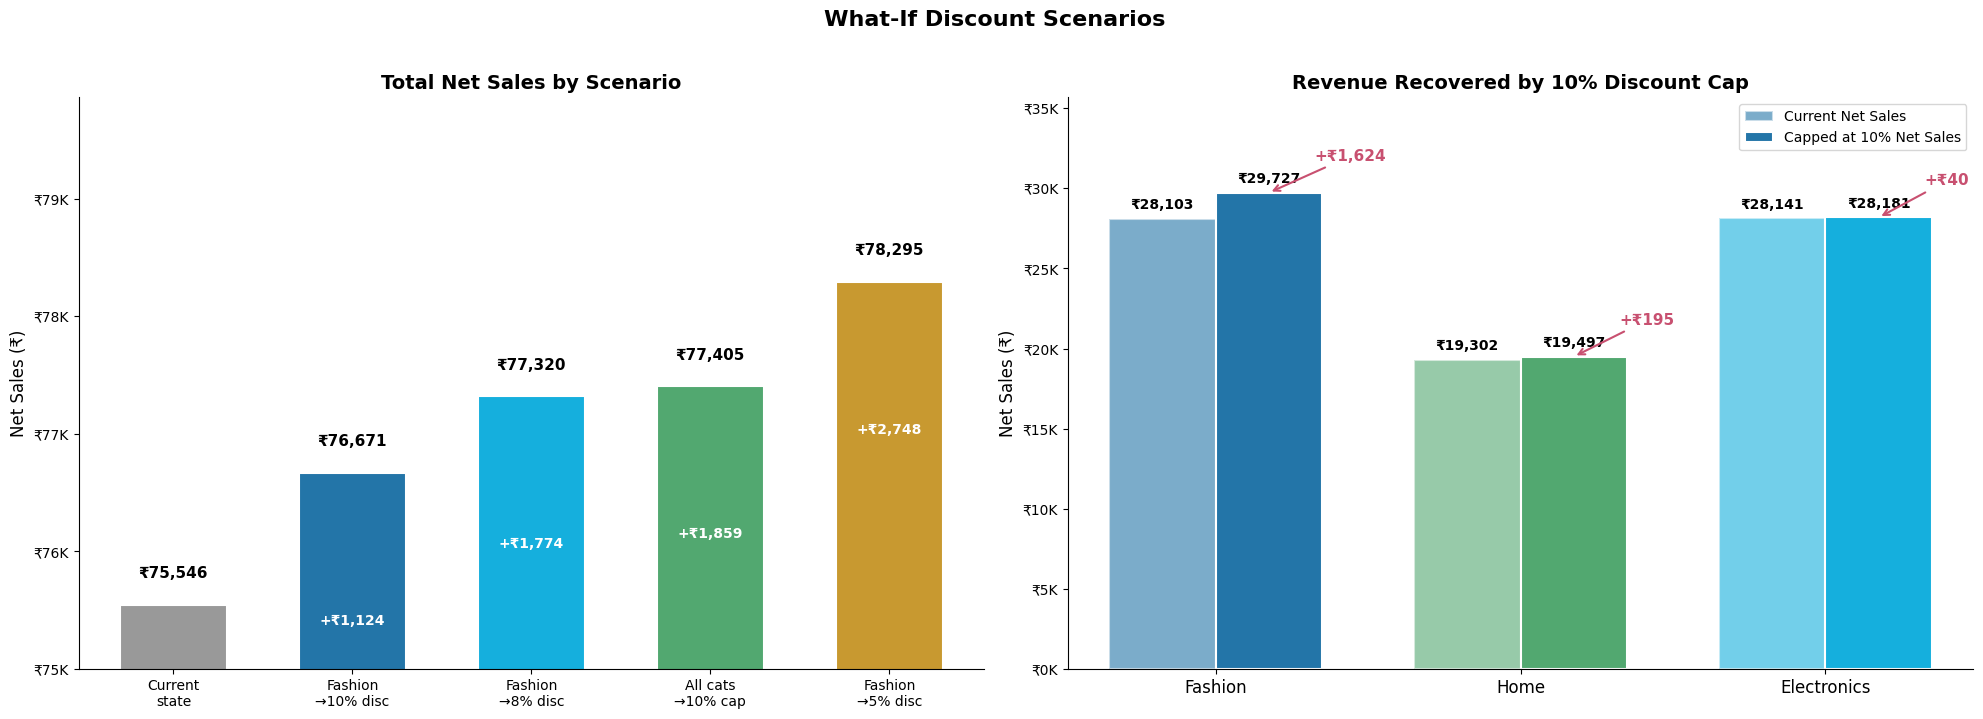

In [0]:
# What-If Scenario Charts
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('What-If Discount Scenarios', fontsize=16, fontweight='bold', y=1.02)

# --- Chart 1: Company-level net sales under each scenario ---
scenarios = ['Current\nstate', 'Fashion\n→10% disc', 'Fashion\n→8% disc', 'All cats\n→10% cap', 'Fashion\n→5% disc']
net_vals = [75546.35, 76670.85, 77320.35, 77405.15, 78294.60]
deltas = [0, 1124.50, 1774.0, 1858.80, 2748.25]
bar_colors = ['#999999', '#2375A8', '#15AFDD', '#52A870', '#C89930']

bars = axes[0].bar(scenarios, net_vals, color=bar_colors, edgecolor='white', linewidth=1.5, width=0.6)
axes[0].set_title('Total Net Sales by Scenario', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Net Sales (₹)', fontsize=12)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}K'))
axes[0].set_ylim(75000, max(net_vals) * 1.02)
for bar, val, delta in zip(bars, net_vals, deltas):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                f'₹{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    if delta > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() - 1200,
                    f'+₹{delta:,.0f}', ha='center', va='top', fontsize=10, color='white', fontweight='bold')
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# --- Chart 2: Revenue recovered by category under 10% cap ---
cat_names = ['Fashion', 'Home', 'Electronics']
cat_recovered = [1624.0, 194.85, 39.95]
cat_current = [28103.0, 19302.40, 28140.95]
cat_capped = [29727.0, 19497.25, 28180.90]
cat_colors2 = ['#2375A8', '#52A870', '#15AFDD']

x = np.arange(len(cat_names))
width = 0.35
bars1 = axes[1].bar(x - width/2, cat_current, width, label='Current Net Sales', color=cat_colors2,
                    edgecolor='white', linewidth=1.5, alpha=0.6)
bars2 = axes[1].bar(x + width/2, cat_capped, width, label='Capped at 10% Net Sales', color=cat_colors2,
                    edgecolor='white', linewidth=1.5)
axes[1].set_title('Revenue Recovered by 10% Discount Cap', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Net Sales (₹)', fontsize=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(cat_names, fontsize=12)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'₹{v/1000:.0f}K'))
axes[1].legend(fontsize=10, loc='upper right')
for i, (cur, cap, rec) in enumerate(zip(cat_current, cat_capped, cat_recovered)):
    axes[1].text(x[i] - width/2, cur + 400, f'₹{cur:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[1].text(x[i] + width/2, cap + 400, f'₹{cap:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[1].annotate(f'+₹{rec:,.0f}', xy=(x[i] + width/2, cap), xytext=(x[i] + width/2 + 0.15, cap + 2000),
                    fontsize=11, fontweight='bold', color='#C85070',
                    arrowprops=dict(arrowstyle='->', color='#C85070', lw=1.5))
axes[1].set_ylim(0, max(cat_capped) * 1.2)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

# What-If Discount Scenario: Results

## Key Question
How would net sales change if Fashion discounts were reduced from ~13.5% (weighted) to 10% of GMV, assuming order volume remains constant?

## Fashion Discount Reduction Scenarios

| Scenario | Avg Disc % | Net Sales | Revenue Recovered |
| --- | --- | --- | --- |
| Current state | 10.8% (simple avg) / 13.5% (weighted) | ₹28,103.00 | — |
| Flat 10% on all Fashion | 10.0% | ₹29,227.50 | +₹1,124.50 |
| Flat 8% on all Fashion | 8.0% | ₹29,877.00 | +₹1,774.00 |
| Flat 5% on all Fashion | 5.0% | ₹30,851.25 | +₹2,748.25 |
| Cap at 10% (only reduce > 10%) | — | ₹29,727.00 | +₹1,624.00 |

> **Note:** The "flat" approach applies a uniform discount to ALL Fashion orders (even those currently at 0% or 5%). The "cap" approach only reduces orders above 10%, preserving low-discount orders. The cap recovers **more revenue** (+₹1,624 vs +₹1,124.50) because it doesn't increase discounts for orders that were already below 10%.

## Company-Level Impact

| Scenario | Total Net Sales | Revenue Delta | Net Margin % |
| --- | --- | --- | --- |
| Current state | ₹75,546.35 | — | 91.3% |
| Fashion → 10% disc (flat) | ₹76,670.85 | +₹1,124.50 | 92.7% |
| Fashion → 8% disc (flat) | ₹77,320.35 | +₹1,774.00 | 93.5% |
| All cats → 10% cap | ₹77,405.15 | +₹1,858.80 | 93.6% |
| Fashion → 5% disc (flat) | ₹78,294.60 | +₹2,748.25 | 94.6% |

## Revenue Recovered by Category (10% Cap)

| Category | Current Net Sales | Capped Net Sales | Revenue Recovered |
| --- | --- | --- | --- |
| Fashion | ₹28,103.00 | ₹29,727.00 | +₹1,624.00 |
| Home | ₹19,302.40 | ₹19,497.25 | +₹194.85 |
| Electronics | ₹28,140.95 | ₹28,180.90 | +₹39.95 |
| **Total** | **₹75,546.35** | **₹77,405.15** | **+₹1,858.80** |

## Top 3 Orders Driving Fashion Recovery (10% Cap)

| Order | Product | Current Disc | Revenue Recovered |
| --- | --- | --- | --- |
| O1030 | Running Shoes | 25% | +₹899.70 |
| O1006 | Running Shoes | 20% | +₹299.90 |
| O1015 | Cotton T-Shirt | 20% | +₹199.60 |

These 3 orders alone account for **₹1,399.20** — 86% of the ₹1,624 Fashion recovery. Running Shoes with 25% discount (O1030) is the single biggest opportunity.

## Findings

1. **Capping Fashion discounts at 10% recovers ₹1,624** — 55% of which comes from a single order (O1030, Running Shoes at 25% discount)
2. **A blanket 10% cap across ALL categories recovers ₹1,858.80** — but Fashion alone accounts for 87% of that, while Electronics and Home contribute only ₹234.80 combined
3. **Aggressive discount reduction (flat 5%) could recover ₹2,748.25** from Fashion alone, but risks impacting order volume — the analysis assumes constant volume, which may not hold
4. **Running Shoes is the primary discount lever** — 4 of 13 Fashion orders have discounts above 10%, and all are Running Shoes orders; the product's premium price (₹2,999) amplifies the impact of high discount rates

## Recommendation

* **Immediate action:** Cap Fashion discounts at 10% (not flat, only reduce orders above 10%) — low-risk, high-reward, recovering ₹1,624
* **Broader action:** Extend the 10% cap to all categories — recovers an additional ₹234.80 from Home and Electronics with minimal disruption
* **Monitor:** Track Running Shoes order volume after capping the 25% discount on O1030-type orders — if volume holds, consider further reduction to 8% or 5%
* **Caution:** This is a static what-if with 40 rows. Real-world price elasticity and customer behavior require A/B testing before committing to broad discount policy changes